# code_217 · Serving follows arrival patterns and decision deadlines

**Book:** section 41.2. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_41_GUIDE.md), [execution evidence](../CHAPTER_41_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_217).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Deployment contracts bind source-fitted transformations, model state, schema and version. Resource measurements are actual observations of this run, separated from deterministic scientific results; no production service or autonomous engineering clearance is claimed. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8017;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8017


## Use stateless and stateful paths deliberately
 Fit a source-scaled linear response model to1,000 generated records with current load/temperature and their interaction. Independent200-record predictions are evaluated as one batch, one record at a time, and an explicit coefficient-only edge evaluator. Verify exact numerical equivalence. These are local callable paths rather than deployed network services. Separately process two assets' timestamped sensor packets with an exponential moving state alpha0.3. A duplicate/stale timestamp is rejected before updating that asset's state, so replay and interleaving do not corrupt another asset's history. Compare every accepted state with an independent causal recurrence. No future packet or final outcome initializes the stream. Arrival deadlines and permitted replay behaviour belong in the consumer's contract.


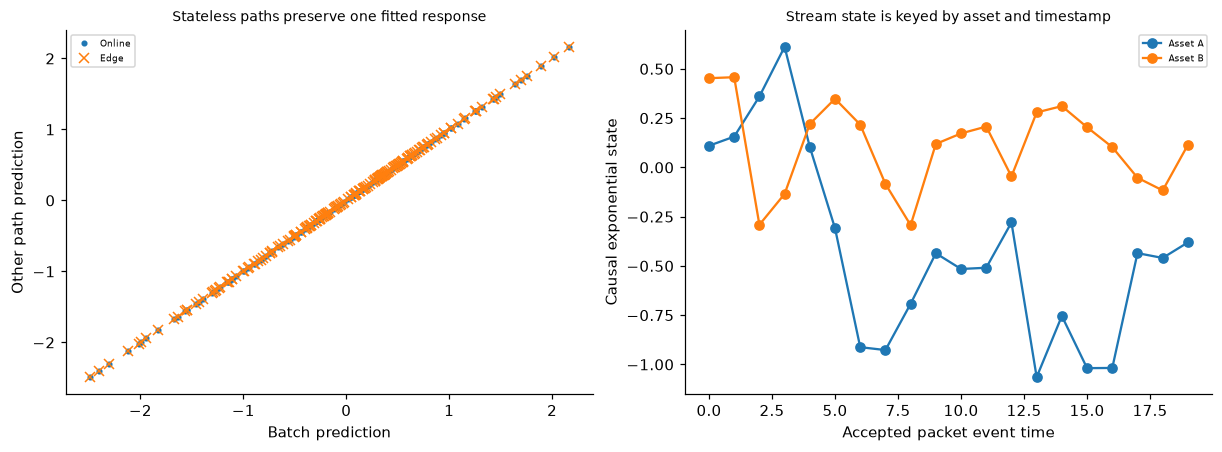

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
xs=rng.normal(size=(1000,2));ys=.8*xs[:,0]-.2*xs[:,1]+.3*xs[:,0]*xs[:,1]+rng.normal(scale=.1,size=1000);xf=rng.normal(size=(200,2));scaler=StandardScaler().fit(np.c_[xs,xs[:,0]*xs[:,1]]);model=Ridge(alpha=.1).fit(scaler.transform(np.c_[xs,xs[:,0]*xs[:,1]]),ys)
def predict(x):return model.predict(scaler.transform(np.c_[x,x[:,0]*x[:,1]]))
batch=predict(xf);online=np.array([predict(x[None])[0] for x in xf]);edge=np.array([float(model.intercept_+(((np.r_[x,x[0]*x[1]]-scaler.mean_)/scaler.scale_)*model.coef_).sum()) for x in xf]);assert np.allclose(batch,online,atol=1e-12) and np.allclose(batch,edge,atol=1e-12);packets=[]
for t in range(20):
    for asset in ['A','B']:packets.append((asset,t,float(rng.normal())))
packets.insert(12,packets[4]);packets.append(('A',3,100.));states={};last={};accepted=[];rejected=0
for asset,t,value in packets:
    if t<=last.get(asset,-1):rejected+=1;continue
    states[asset]=value if asset not in states else .3*value+.7*states[asset];last[asset]=t;accepted.append((asset,t,value,states[asset]))
for asset in ['A','B']:
    previous=None
    for a,t,value,state in accepted:
        if a!=asset:continue
        previous=value if previous is None else .3*value+.7*previous;assert np.isclose(previous,state)
assert rejected==2 and len(accepted)==40;RESULTS.update(source_records=1000,final_stateless_records=200,batch_online_max_difference=float(np.max(abs(batch-online))),batch_edge_max_difference=float(np.max(abs(batch-edge))),stream_accepted_packets=40,stream_duplicate_or_stale_rejections=2,stream_assets=2,stream_uses_future_packets=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(batch,online,'.',label='Online');axes[0].plot(batch,edge,'x',label='Edge');axes[0].set(xlabel='Batch prediction',ylabel='Other path prediction',title='Stateless paths preserve one fitted response');axes[0].legend(fontsize=6)
for asset in ['A','B']:
    rows=[r for r in accepted if r[0]==asset];axes[1].plot([r[1] for r in rows],[r[3] for r in rows],'o-',label=f'Asset {asset}')
axes[1].set(xlabel='Accepted packet event time',ylabel='Causal exponential state',title='Stream state is keyed by asset and timestamp');axes[1].legend(fontsize=6);plt.show()


## Include graph construction, context retrieval and solver calls in the path
 Construct spatial graphs from source-only coordinates and a fixed radius, excluding self-loops in the neighbour mean. Fit a linear nodal-response model to40 independent generated20-node source graphs using load, neighbour load and degree. A new30-node daily graph is constructed at inference, then scored with the same definition. Separately retrieve eight nearest source records for each query and form a declared inverse-distance context response; this is an actual retrieval baseline, not a pretrained foundation model. Finally solve a positive three-node free stiffness system for a selected load case, verify equilibrium, and catch a deliberately singular solver fixture. Graph construction, retrieval and solving are computation that must be measured when the consumer uses them. No final label selects graph radius or context size.


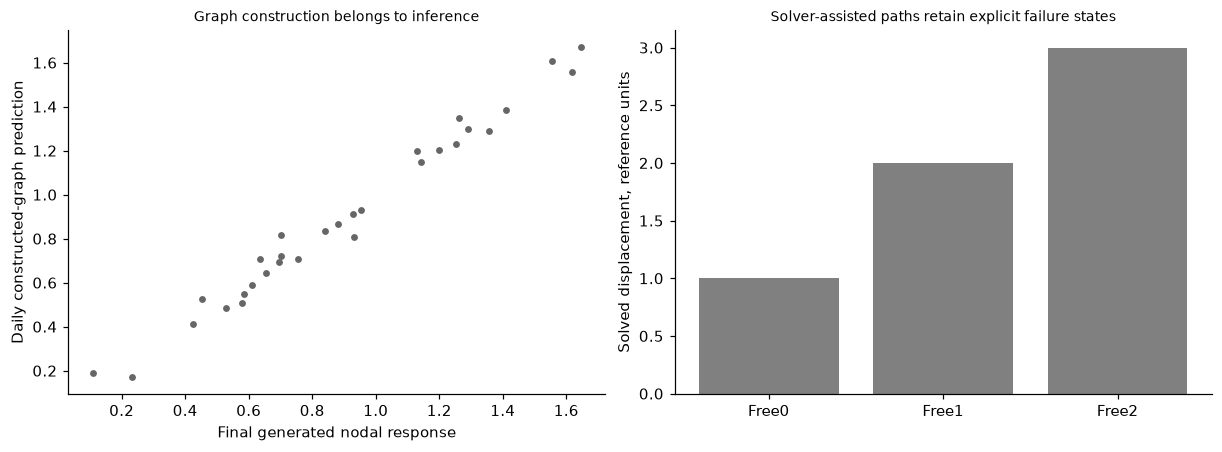

In [3]:
from sklearn.neighbors import NearestNeighbors
def graph(n):
    xy=rng.uniform(0,5,(n,2));load=rng.uniform(0,2,n);dist=np.linalg.norm(xy[:,None]-xy[None],axis=-1);A=((dist<1.5)&(dist>0)).astype(float);degree=A.sum(1);neighbour=(A@load)/np.maximum(degree,1);features=np.c_[load,neighbour,degree];y=.8*load+.3*neighbour-.02*degree+rng.normal(scale=.05,size=n);return features,y,A
source_graphs=[graph(20) for _ in range(40)];gx=np.concatenate([x for x,y,A in source_graphs]);gy=np.concatenate([y for x,y,A in source_graphs]);graph_model=Ridge(alpha=.1).fit(gx,gy);gfinal,gt,adj=graph(30);gp=graph_model.predict(gfinal);assert np.allclose(adj,adj.T) and np.all(np.diag(adj)==0);retriever=NearestNeighbors(n_neighbors=8).fit(xs);distance,index=retriever.kneighbors(xf[:20]);weights=1/np.maximum(distance,1e-6);context=(weights*ys[index]).sum(1)/weights.sum(1);assert index.max()<1000 and np.all(np.isfinite(context));K=np.array([[2.,-1,0],[-1,2,-1],[0,-1,1]]);force=np.array([0.,0,1.]);solution=np.linalg.solve(K,force);assert np.allclose(K@solution,force);failure_status=None
try:np.linalg.solve(np.zeros((3,3)),force)
except np.linalg.LinAlgError:failure_status='solver_failed_defer'
assert failure_status=='solver_failed_defer';RESULTS.update(source_graphs=40,source_nodes_per_graph=20,final_graph_nodes=30,final_graph_RMSE=float(np.sqrt(np.mean((gp-gt)**2))),retrieval_context_records=8,retrieval_queries=20,retrieved_prediction_first_five=context[:5].tolist(),solver_displacement=solution.tolist(),singular_solver_status=failure_status,graph_radius=1.5,context_baseline_is_not_pretrained_foundation_model=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].scatter(gt,gp,color='.4',s=12);axes[0].set(xlabel='Final generated nodal response',ylabel='Daily constructed-graph prediction',title='Graph construction belongs to inference');axes[1].bar(range(3),solution,color='.5');axes[1].set(xticks=range(3),xticklabels=['Free0','Free1','Free2'],ylabel='Solved displacement, reference units',title='Solver-assisted paths retain explicit failure states');plt.show()


In [4]:
summary={'example_id':'code_217','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual batch online and compact edge numerical inference equivalence', 'per-asset causal streaming state with duplicate and stale rejection', 'actual daily graph construction neighbour aggregation and source-context retrieval', 'explicit solver-assisted response path with its own failure contract'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual batch online and compact edge numerical inference equivalence", "per-asset causal streaming state with duplicate and stale rejection", "actual daily graph construction neighbour aggregation and source-context retrieval", "explicit solver-assisted response path with its own failure contract"], "elapsed_seconds": 0.358, "example_id": "code_217", "hardware": "Darwin arm64 CPU", "resource_measurements": {}, "results": {"batch_edge_max_difference": 0.0, "batch_online_max_difference": 0.0, "context_baseline_is_not_pretrained_foundation_model": true, "final_graph_RMSE": 0.05385648665841734, "final_graph_nodes": 30, "final_stateless_records": 200, "graph_radius": 1.5, "retrieval_context_records": 8, "retrieval_queries": 20, "retrieved_prediction_first_five": [-0.26937754557375776, -0.8373817324391728, -0.6875202045707544, -0.23185946447860936, -1.1277146202306843], "singular_solver_status": "solver_failed_defer", "solver_displacement": 